In [ ]:
import pandas as pd
#df = pd.read_excel('电信用户流失.xlsx', engine='openpyxl')
#df.to_csv('电信用户流失.csv', index=False, encoding='utf-8-sig')
df = pd.read_csv('data.csv', encoding='utf-8-sig',quoting=3)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip('"')
    print(col,df[col].str.strip().unique()[:10])
df.columns = df.columns.str.strip('"')
df.head()
df.describe()
df.info()
df.tail()
print(df["Churn"].value_counts())

"customerID <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU']
Length: 10, dtype: str
gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <StringArray>
['No', 'Yes', 'No interne

/var/folders/97/fnzt0g_j6118scp4g3917shw0000gn/T/ipykernel_2322/2973554661.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object']).columns:


In [2]:
print(df['TotalCharges'].head(20))
print(df['TotalCharges'].tail(20))
print(df['TotalCharges'].isnull().sum())
print("空字符数量：", (df['TotalCharges'] == ' ').sum())
df["TotalCharges"]=pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].isnull().sum())

0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
15    7895.15
16    1022.95
17    7382.25
18     528.35
19     1862.9
Name: TotalCharges, dtype: str
7023     6479.4
7024    3626.35
7025     1679.4
7026     403.35
7027     931.55
7028    4326.25
7029     263.05
7030      39.25
7031     3316.1
7032      75.75
7033    2625.25
7034    6886.25
7035     1495.1
7036      743.3
7037     1419.4
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: TotalCharges, dtype: str
0
空字符数量： 11
11


In [3]:
print(
    df.loc[df["TotalCharges"].isnull(),
           ["tenure", "MonthlyCharges", "Churn"]]
)

      tenure  MonthlyCharges Churn
488        0           52.55    No
753        0           20.25    No
936        0           80.85    No
1082       0           25.75    No
1340       0           56.05    No
3331       0           19.85    No
3826       0           25.35    No
4380       0           20.00    No
5218       0           19.70    No
6670       0           73.35    No
6754       0           61.90    No


In [4]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [5]:
print("重复行：", df.duplicated().sum())
print("重复ID:", df.duplicated(subset="customerID").sum())
print(df[["tenure", "MonthlyCharges","TotalCharges"]].describe())

重复行： 0
重复ID: 0
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7032.000000
mean     32.371149       64.761692   2283.300441
std      24.559481       30.090047   2266.771362
min       0.000000       18.250000     18.800000
25%       9.000000       35.500000    401.450000
50%      29.000000       70.350000   1397.475000
75%      55.000000       89.850000   3794.737500
max      72.000000      118.750000   8684.800000


In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

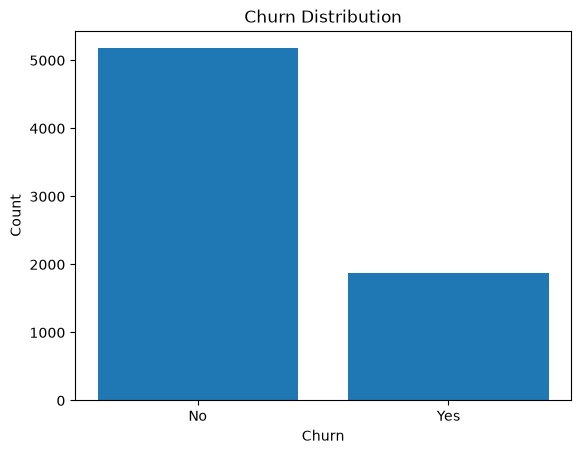

In [7]:
import matplotlib.pyplot as plt
churn_counts = df["Churn"].value_counts().sort_index()
#索引的语法问题！！！！！！
plt.bar(["No","Yes"], churn_counts)
plt.xlabel("Churn")
plt.ylabel("Count")
plt.title("Churn Distribution")
plt.show()

Churn                  0         1
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319


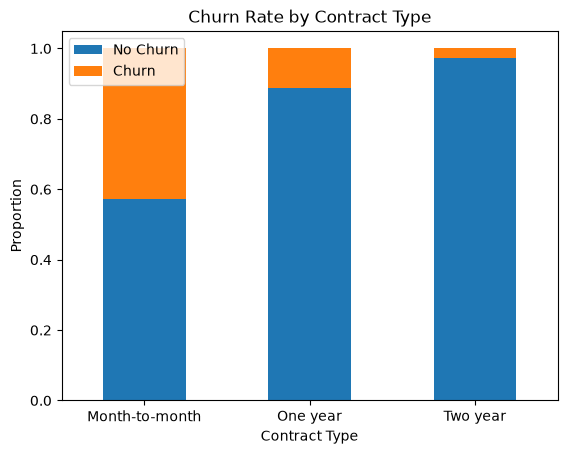

In [8]:
contract_churn = pd.crosstab(
    df["Contract"],df["Churn"],normalize="index"
)
print(contract_churn)
contract_churn.plot(kind="bar", stacked=True)#堆叠柱状图
plt.xlabel("Contract Type")
plt.ylabel("Proportion")
plt.title("Churn Rate by Contract Type")
plt.legend(["No Churn", "Churn"])#图例
plt.xticks(rotation=0)#标签文字旋转
plt.show()

In [9]:
contract_churn_rate = (df.groupby("Contract")["Churn"]
                       .mean()
                       .sort_values(ascending=False))#降序排列
print(contract_churn_rate)

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


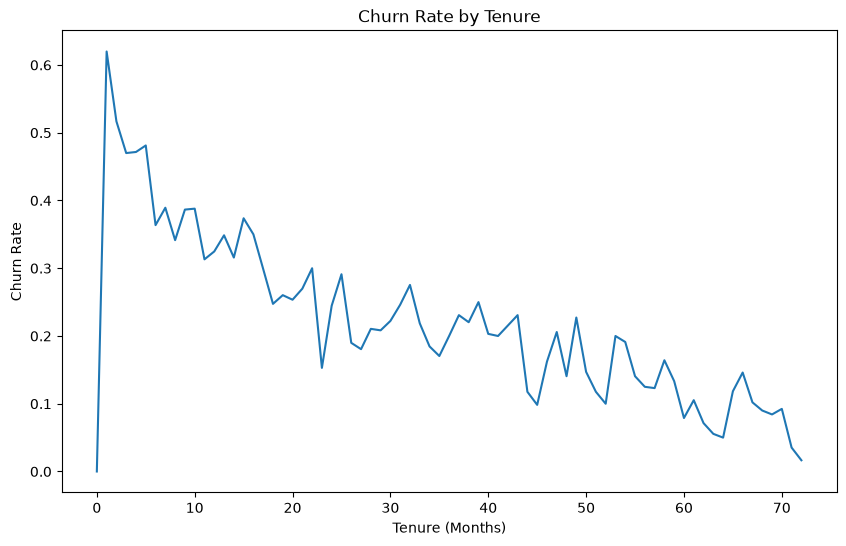

In [10]:
tenure_churn = df.groupby("tenure")["Churn"].mean()
#print(tenure_churn)
plt.figure(figsize = (10, 6))
plt.plot(tenure_churn.index, tenure_churn.values)
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate")
plt.title("Churn Rate by Tenure")
plt.show()

In [11]:
tenure_analysis = pd.DataFrame({
    "user_count":df.groupby("tenure").size(),
    "churn_rate":df.groupby("tenure")["Churn"].mean()
})
print(tenure_analysis)

        user_count  churn_rate
tenure                        
0               11    0.000000
1              613    0.619902
2              238    0.516807
3              200    0.470000
4              176    0.471591
...            ...         ...
68             100    0.090000
69              95    0.084211
70             119    0.092437
71             170    0.035294
72             362    0.016575

[73 rows x 2 columns]


In [12]:
bins = [0, 12, 24, 36, 48, 60, 72]
labels = ["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
df["tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)
tenure_group_analysis =(
    df.groupby("tenure_group",observed=True)["Churn"].agg(["count","mean"])
)
print(tenure_group_analysis)

              count      mean
tenure_group                 
0-12           2186  0.474382
13-24          1024  0.287109
25-36           832  0.216346
37-48           762  0.190289
49-60           832  0.144231
61-72          1407  0.066098


In [13]:
tenure_analysis = pd.DataFrame({
    "Churn Rate": df.groupby("tenure")["Churn"].mean(),
    "user_count": df.groupby("tenure").size()
})
print(tenure_analysis)

        Churn Rate  user_count
tenure                        
0         0.000000          11
1         0.619902         613
2         0.516807         238
3         0.470000         200
4         0.471591         176
...            ...         ...
68        0.090000         100
69        0.084211          95
70        0.092437         119
71        0.035294         170
72        0.016575         362

[73 rows x 2 columns]


In [14]:
print(df["MonthlyCharges"].describe())

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64


<Figure size 1000x600 with 0 Axes>

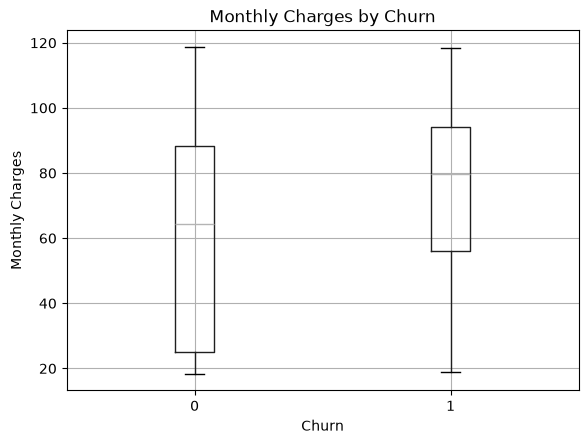

       count       mean        std  median
Churn                                     
0       5174  61.265124  31.092648  64.425
1       1869  74.441332  24.666053  79.650


In [15]:
plt.figure(figsize=(10, 6))
df.boxplot(column = "MonthlyCharges",by = 'Churn')
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.title("Monthly Charges by Churn")
plt.suptitle("")  # Remove the default title to avoid overlap
plt.show()
monthly_charges_analysis = df.groupby("Churn")["MonthlyCharges"].agg(["count", "mean", "std","median"])
print(monthly_charges_analysis)

                 count      mean
InternetService                 
DSL               2421  0.189591
Fiber optic       3096  0.418928
No                1526  0.074050


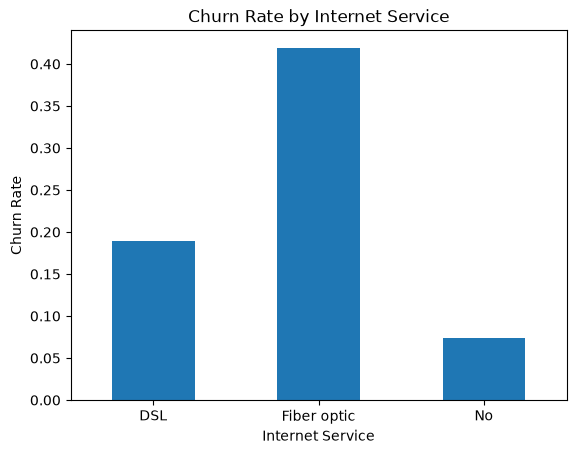

In [16]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .agg(["count", "mean"])
)
print(internet_churn)  
internet_churn["mean"].plot(kind="bar")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate")
plt.title("Churn Rate by Internet Service")
plt.xticks(rotation=0)  # Rotate x-axis labels for better readability
plt.show()

In [17]:
x = df.drop(columns=["customerID","Churn"])
y = df["Churn"]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,    
    test_size = 0.2,
    random_state = 42,#随机种子，控制拆分结果一致
    stratify = y#分层，按比例抽样
)
print("训练集样本数:", x_train.shape)
print("测试集样本数:", x_test.shape)

训练集样本数: (5634, 20)
测试集样本数: (1409, 20)


In [18]:
from sklearn.metrics import accuracy_score#准确率计算函数
y_pred_baseline = [0] * len(y_test)

baseline_accuracy = accuracy_score(y_test,y_pred_baseline)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.7345635202271115


In [19]:
numeric_features = [
    "SeniorCitizen","tenure","MonthlyCharges","TotalCharges"
]
categorical_features = [
    "gender","Partner","Dependents","PhoneService","MultipleLines","InternetService","OnlineSecurity","OnlineBackup","DeviceProtection",
    "TechSupport","StreamingTV","StreamingMovies","Contract","PaperlessBilling","PaymentMethod"
]
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

preprocessor = ColumnTransformer(
    transformers = [
       ( 
            "num",
            StandardScaler(),
            numeric_features
       ),
       ( 
            "cat",
            OneHotEncoder( handle_unknown="ignore" ),
            categorical_features
       )
    ]
)

from sklearn.linear_model import LogisticRegression#逻辑分类器
from sklearn.pipeline import Pipeline#流水线
logistic_model = Pipeline(
    steps = [
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000,random_state=42)#最大迭代
        )
    ]
)
logistic_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'tenure_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [20]:
y_pred = logistic_model.predict(x_test)
y_proba = logistic_model.predict_proba(x_test)[:,1]#预测为1的概率
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,classification_report)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-Score: 0.6040462427745664
ROC AUC: 0.8421349040274871

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [21]:
import numpy as np

class MylogisiticRegression:
    def __init__(self,learning_rate = 0.01,n_iteration = 1000):
        self.learning_rate = learning_rate
        self.n_itration = n_iteration#迭代下降次数

    def sigmoid(self,z):
        return 1 / (1 + np.exp(-z))

    def fit(self,X,y):
        n_samples,n_features = X.shape#样本数特征数
        self.w = np.zeros(n_features)
        self.b = 0
        for _ in range(self.n_itration):
            z = X @ self.w + self.b
            p =self.sigmoid(z)
            dw = (1/n_samples) * (X.T @ (p - y))
            db = (1/n_samples) * np.sum(p - y)
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db
        return self

    def predict_proba(self,X):
        z = X @ self.w + self.b
        return self.sigmoid(z)
    def predict(self,X):
        p = self.predict_proba(X)
        return (p >= 0.5).astype(int)#转1否则转0

In [22]:
X_train_processed = preprocessor.fit_transform(x_train)
X_test_processed = preprocessor.transform(x_test)
print(X_train_processed.shape)
print(X_test_processed.shape)

(5634, 45)
(1409, 45)


In [23]:
#x_train_np = X_train_processed.toarray()#toarray()将稀疏矩阵转换为密集矩阵,原本已是普通矩阵会报错
#x_test_np = X_test_processed.toarray()
X_train_np = np.asarray(X_train_processed)
X_test_np = np.asarray(X_test_processed)
y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()
print(X_train_processed.shape)
print(X_test_processed.shape)

(5634, 45)
(1409, 45)


In [24]:
import numpy as np
class MyLogisiticRegression:
    def __init__(self,learning_rate=0.01,n_iterations =1000):
        self.learning_rate = learning_rate
        self.n_iteratons =n_iterations

        self.w =None
        self.b =None
        self.loss_history = []

    def sigmoid(self,z):
        z = np.clip(z,-500,500)
        return 1/(1+np.exp(-z))
    def compute_loss(self,y,p):
        eps = 1e-15

        p= np.clip(p,eps,1-eps)#极小正数，限定范围内防止p为0或1导致log(0)报错
        loss = -np.mean(y*np.log(p)+(1-y)* np.log(1-p))#交叉损失殇
        return loss
    def fit(self,X,y):
        n_samples,n_features =X.shape
        self.w =np.zeros(n_features)
        self.b =0.0
        self.loss_history = []
        for i in range(self.n_iteratons):
            z =X@self.w +self.b
            p =self.sigmoid(z)
            loss = self.compute_loss(y,p)
            self.loss_history.append(loss)
            dw =(1/n_samples)*X.T@(p-y)
            db =(1/n_samples)*np.sum(p-y)

            self.w -= self.learning_rate *dw
            self.b -= self.learning_rate *db

        return self
    def predict_proba(self,X):
        z =X@self.w +self.b
        return self.sigmoid(z)
    def predict(self,X):
        p = self.predict_proba(X)
        return(p>=0.5).astype(int)

最终loss: 0.41675866179935633


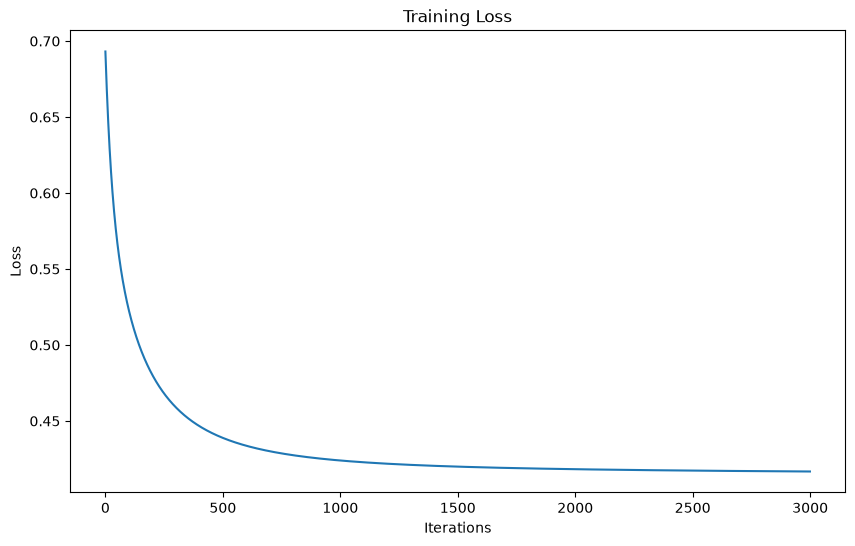

In [25]:
my_lr =MyLogisiticRegression(learning_rate=0.01,n_iterations=3000)
my_lr.fit(X_train_np,y_train_np)
print("最终loss:",my_lr.loss_history[-1])
plt.figure(figsize=(10,6))
plt.plot(my_lr.loss_history)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

In [26]:
my_y_pred = my_lr.predict(X_test_np)
my_y_proba = my_lr.predict_proba(X_test_np)
print(classification_report(y_test_np,my_y_pred))
print("ROC-AUC:", roc_auc_score(y_test_np, my_y_proba))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.64      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8377586607765636


In [27]:
from sklearn.linear_model import LogisticRegression
sklearn_lr = LogisticRegression(max_iter=1000,random_state=42,solver='lbfgs')
sklearn_lr.fit(X_train_np,y_train_np)
sklearn_y_pred = sklearn_lr.predict(X_test_np)#二分类类别标签
sklearn_y_proba = sklearn_lr.predict_proba(X_test_np)[:,1]#原始概率

print("sklearn accuracy:", accuracy_score(y_test_np, sklearn_y_pred))
print("sklearn ROC-AUC:", roc_auc_score(y_test_np, sklearn_y_proba))
print("sklearn precid=sion:", precision_score(y_test_np, sklearn_y_pred))
print("sklearn recall:", recall_score(y_test_np, sklearn_y_pred))
print("sklearn F1-score:", f1_score(y_test_np, sklearn_y_pred))

sklearn accuracy: 0.8055358410220014
sklearn ROC-AUC: 0.8421349040274871
sklearn precid=sion: 0.6572327044025157
sklearn recall: 0.5588235294117647
sklearn F1-score: 0.6040462427745664


In [28]:
from sklearn.metrics import precision_score,recall_score,f1_score

y_test_prob = sklearn_lr.predict_proba(X_test_np)[:,1]
thresholds = [0.2,0.3,0.4,0.5,0.6,0.7,0.8]
for threshold in thresholds:
    y_pred =(y_test_prob>=threshold).astype(int)
    precision = precision_score(y_test_np,y_pred)
    recall = recall_score(y_test_np,y_pred)
    f1 = f1_score(y_test_np,y_pred)

    print(f"threshold ={threshold:.1f}|"
          f"precision ={precision:.3f}|"
          f"recall = {recall:.3f}|"
          f"f1 ={f1:.3f}") 

threshold =0.2|precision =0.467|recall = 0.856|f1 =0.604
threshold =0.3|precision =0.519|recall = 0.754|f1 =0.615
threshold =0.4|precision =0.568|recall = 0.668|f1 =0.614
threshold =0.5|precision =0.657|recall = 0.559|f1 =0.604
threshold =0.6|precision =0.718|recall = 0.401|f1 =0.515
threshold =0.7|precision =0.742|recall = 0.184|f1 =0.296
threshold =0.8|precision =0.769|recall = 0.027|f1 =0.052


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

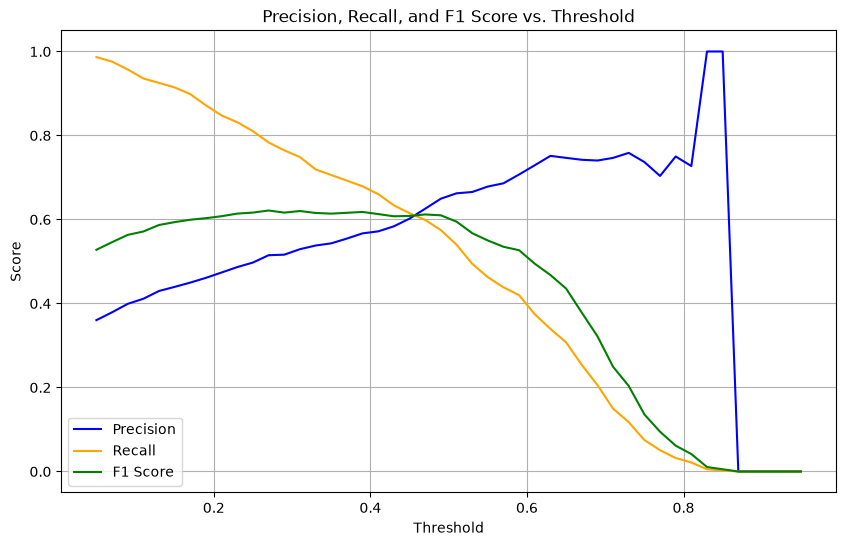

In [29]:
import numpy as np
import matplotlib.pyplot as plt

thresholds = np.arange(0.05, 0.96, 0.02)
precisions = []
recalls = []
f1_scores = []

for threshold in thresholds:
    y_pred = (y_test_prob >= threshold).astype(int)
    precisions.append(precision_score(y_test_np, y_pred))
    recalls.append(recall_score(y_test_np, y_pred))
    f1_scores.append(f1_score(y_test_np, y_pred))

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='blue')
plt.plot(thresholds, recalls, label='Recall', color='orange')
plt.plot(thresholds, f1_scores, label='F1 Score', color='green')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall, and F1 Score vs. Threshold')
plt.legend()#图例
plt.grid()#网格
plt.show()

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold,cross_validate
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

cv_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=3000, solver='lbfgs',penalty=None))#关闭正则化，数学算法最优参数，lbfgs，拟牛顿法
    ]
)


cv =StratifiedKFold (n_splits = 5,shuffle = True, random_state=42)#打乱样本
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_results = cross_validate(cv_pipeline, x_train, y_train, cv=cv, scoring=scoring, return_train_score=True)

for i in range(5):
    print(f"Fold {i+1}:")
    print(f"  Accuracy: {cv_results['test_accuracy'][i]:.4f}")
    print(f"  Precision: {cv_results['test_precision'][i]:.4f}")
    print(f"  Recall: {cv_results['test_recall'][i]:.4f}")
    print(f"  F1 Score: {cv_results['test_f1'][i]:.4f}")
    print(f"  ROC AUC: {cv_results['test_roc_auc'][i]:.4f}")
print("\n======== Mean ± Std ========")
for metric in scoring:
    scores = cv_results[f'test_{metric}']
    print(f"{metric}:")
    print(f"  Mean: {scores.mean():.4f}  {scores.std():.4f}")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

Fold 1:
  Accuracy: 0.8021
  Precision: 0.6520
  Recall: 0.5452
  F1 Score: 0.5938
  ROC AUC: 0.8489
Fold 2:
  Accuracy: 0.7826
  Precision: 0.6071
  Recall: 0.5117
  F1 Score: 0.5554
  ROC AUC: 0.8251
Fold 3:
  Accuracy: 0.8021
  Precision: 0.6570
  Recall: 0.5318
  F1 Score: 0.5878
  ROC AUC: 0.8408
Fold 4:
  Accuracy: 0.8181
  Precision: 0.6691
  Recall: 0.6221
  F1 Score: 0.6447
  ROC AUC: 0.8637
Fold 5:
  Accuracy: 0.8126
  Precision: 0.6880
  Recall: 0.5385
  F1 Score: 0.6041
  ROC AUC: 0.8532

======== Mean ± Std ========
accuracy:
  Mean: 0.8035  0.0121
precision:
  Mean: 0.6547  0.0268
recall:
  Mean: 0.5498  0.0378
f1:
  Mean: 0.5972  0.0288
roc_auc:
  Mean: 0.8463  0.0129


In [31]:
C_values = [0.01, 0.1, 1, 10, 100]
results = []
for C in C_values:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=3000, solver='lbfgs', C=C))
        ]
    )
    cv_results = cross_validate(model,x_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    train_f1 = cv_results['train_f1']
    val_f1 = cv_results['test_f1']
    results.append({
        'C': C,
        'train_f1_mean': train_f1.mean(),
        'val_f1_mean': val_f1.mean(),
        'val_f1_std':val_f1.std(),
        'f1_gap': train_f1.mean() - val_f1.mean(),
        "train_auc": cv_results['train_roc_auc'].mean(),
        "val_auc": cv_results['test_roc_auc'].mean()
    })
results_df = pd.DataFrame(results)
print(results_df)

        C  train_f1_mean  val_f1_mean  val_f1_std    f1_gap  train_auc  \
0    0.01       0.584758     0.581239    0.026926  0.003518   0.845558   
1    0.10       0.599704     0.588906    0.028287  0.010798   0.848579   
2    1.00       0.602298     0.592329    0.029851  0.009969   0.849610   
3   10.00       0.602603     0.597540    0.030248  0.005063   0.849974   
4  100.00       0.603233     0.597161    0.028832  0.006072   0.849979   

    val_auc  
0  0.843468  
1  0.845486  
2  0.846201  
3  0.846391  
4  0.846327  


In [32]:
lr_l1 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(solver='liblinear', penalty='l1', C=1.0))#L1正则化,坐标下降优化
    ]
)
l1_result = cross_validate(lr_l1, x_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
for metric in scoring:
    scores = l1_result[f"test_{metric}"]
    print(f"{metric}:" f"{scores.mean():.4f} ± {scores.std():.4f}")

lr_l1.fit(x_train, y_train)
feature_names = (lr_l1.named_steps['preprocessor'].get_feature_names_out())#特征名
print(len(feature_names))
print(feature_names)
coef = (lr_l1.named_steps['classifier'].coef_[0])#模型系数
coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coef})
coef_df = coef_df.sort_values(by='coefficient', ascending=False).head(15)
zero_mask = np.isclose(coef,0,atol=1e-8)#判断浮点数是否近似相等，极小判为0
zero_count = zero_mask.sum()
total_count = len(coef)
print("总特征数：" + str(total_count))
print("系数为零的特征数：", zero_count)
print("系数为零的特征比例：", zero_count / total_count)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

accuracy:0.8026 ± 0.0125
precision:0.6541 ± 0.0286
recall:0.5445 ± 0.0407
f1:0.5936 ± 0.0303
roc_auc:0.8460 ± 0.0125
45
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service'
 'cat__OnlineSecurity_Yes' 'cat__OnlineBackup_No'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No' 'cat__DeviceProtection_No internet service'
 'cat__DeviceProtection_Yes' 'cat__TechSupport_No'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes'
 'cat__StreamingTV_No' 'cat__StreamingTV_No internet service'
 'cat__StreamingTV_Yes'

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [33]:
C_values = [0.01,0.1,1,10,100]
l1_results =[]
for C in C_values:
    model = Pipeline(
        steps = [
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=3000, solver='liblinear', C=C, penalty='l1'))
        ]
    )
    cv_results = cross_validate(model, x_train, y_train, cv=cv, scoring=scoring)
    model.fit(x_train, y_train)
    feature_names = model.named_steps['preprocessor'].get_feature_names_out()
    coef = model.named_steps['classifier'].coef_[0]
    zero_mask = np.isclose(coef, 0, atol=1e-8)
    l1_results.append({
        "C": C,
        "accuracy": cv_results["test_accuracy"].mean(),
        "f1": cv_results["test_f1"].mean(),
        "precision": cv_results["test_precision"].mean(),
        "recall": cv_results["test_recall"].mean(),
        "zero_count": zero_mask.sum(),
        "sparsity":zero_mask.mean(),
        "ROC_AUC": cv_results["test_roc_auc"].mean(),
        "f1_std": cv_results["test_f1"].std()
    })
l1_results_df = pd.DataFrame(l1_results)
print(l1_results_df)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

        C  accuracy        f1  precision    recall  zero_count  sparsity  \
0    0.01  0.796238  0.523087   0.690926  0.421405          35  0.777778   
1    0.10  0.800853  0.584097   0.654482  0.528428          26  0.577778   
2    1.00  0.802452  0.593105   0.653834  0.543813          15  0.333333   
3   10.00  0.803338  0.596279   0.654647  0.548495           7  0.155556   
4  100.00  0.803693  0.597378   0.655199  0.549833           1  0.022222   

    ROC_AUC    f1_std  
0  0.826111  0.012243  
1  0.844557  0.031360  
2  0.845999  0.030460  
3  0.846317  0.029851  
4  0.846356  0.028765  


In [34]:
from sklearn.model_selection import GridSearchCV
lr_pipeline = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=3000, solver='liblinear'))
    ]
)
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l1", "l2"]
}
scoring = "f1"
grid_search = GridSearchCV(estimator=lr_pipeline, param_grid=param_grid, scoring=scoring, cv=cv, n_jobs=-1,return_train_score=True)
grid_search.fit(x_train, y_train)
print("Best C:", grid_search.best_params_['classifier__C'])
print("Best CV F1 :", grid_search.best_score_)
results = pd.DataFrame(grid_search.cv_results_)
results_table = results[["param_classifier__C", "param_classifier__penalty", "mean_test_score", 
                         "std_test_score", "mean_train_score", "std_train_score","rank_test_score"]].sort_values(by="param_classifier__C")
print(results_table)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

Best C: 100
Best CV F1 : 0.5973782660853237
   param_classifier__C param_classifier__penalty  mean_test_score  \
0                 0.01                        l1         0.523087   
1                 0.01                        l2         0.581594   
2                 0.10                        l1         0.584636   
3                 0.10                        l2         0.589204   
4                 1.00                        l1         0.592891   
5                 1.00                        l2         0.592340   
6                10.00                        l1         0.596804   
7                10.00                        l2         0.596771   
8               100.00                        l1         0.597378   
9               100.00                        l2         0.597378   

   std_test_score  mean_train_score  std_train_score  rank_test_score  
0        0.012243          0.524401         0.006816               10  
1        0.026374          0.588006         0.008191

In [35]:
import numpy as np
def entropy(y):
    values,counts = np.unique(y, return_counts=True)#返回不重复元素
    probabilities = counts / len(y)
    ent = 0.0
    for p in probabilities:
        if p > 0:
            ent -= p * np.log2(p)
    return ent
def information_gain(y,left_y,right_y):
    n = len(y)
    n_left = len(left_y)
    n_right = len(right_y)
    weighted_entropy = (n_left / n) * entropy(left_y) + (n_right / n) * entropy(right_y)
    gain = entropy(y) - weighted_entropy
    return gain

In [36]:
def best_split_numeric(X, y):
    sorted_values = np.sort(np.unique(X))
    best_gain = -1
    best_threshold = None
    for i in range(len(sorted_values)-1):
        threshold = (sorted_values[i] + sorted_values[i+1]) / 2
        left_mask = X <= threshold
        right_mask = X > threshold
        y_left = y[left_mask]
        y_right = y[right_mask]
        if len(y_left) == 0 or len(y_right) == 0:
            continue
        gain = information_gain(y, y_left, y_right)
        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold
    return best_threshold, best_gain
threshold,gain = best_split_numeric(
    x_train["tenure"].values, y_train.values
)
print("Best threshold for tenure:", threshold)
print("最大信息增益：",gain)

Best threshold for tenure: 22.5
最大信息增益： 0.07240107326664269


In [37]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion="entropy",random_state=42)#分裂准则，信息增益
dt.fit(X_train_np,y_train_np)
y_pred = dt.predict(X_test_np)#输出类别标签
print("Accuracy:",accuracy_score(y_test_np,y_pred))
print("Precision:",precision_score(y_test_np,y_pred))
print("Recall:",recall_score(y_test_np,y_pred))
print("F1:",f1_score(y_test_np,y_pred))
train_pred = dt.predict(X_train_np)
test_pred = dt.predict(X_test_np)
print("Train Accuracy:",accuracy_score(y_train_np,train_pred))
print("Train f1:",f1_score(y_train_np,train_pred))
print("Test Accuracy:",accuracy_score(y_test_np,test_pred))
print("Test f1:",f1_score(y_test_np,test_pred))

Accuracy: 0.730305180979418
Precision: 0.4918032786885246
Recall: 0.48128342245989303
F1: 0.4864864864864865
Train Accuracy: 0.9980475683351083
Train f1: 0.996309963099631
Test Accuracy: 0.730305180979418
Test f1: 0.4864864864864865


In [38]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

depths = [1,2,3,4,5,6,8,10,15,20]
train_f1_scores = []
test_f1_scores = []
for depth in depths:
    dt = DecisionTreeClassifier(criterion="entropy",max_depth=depth,random_state=42)
    dt.fit(X_train_np,y_train_np)
    train_pred = dt.predict(X_train_np)
    test_pred = dt.predict(X_test_np)
    train_f1 = f1_score(y_train_np,train_pred)
    test_f1 = f1_score(y_test_np,test_pred)
    train_f1_scores.append(train_f1)
    test_f1_scores.append(test_f1)
    print(f"max_depth= {depth:2d}|"
          f"Train F1 = {train_f1:.4f}|"
          f"Test F1 = {test_f1:.4f}")

max_depth=  1|Train F1 = 0.0000|Test F1 = 0.0000
max_depth=  2|Train F1 = 0.5871|Test F1 = 0.5585
max_depth=  3|Train F1 = 0.4794|Test F1 = 0.4623
max_depth=  4|Train F1 = 0.5406|Test F1 = 0.5357
max_depth=  5|Train F1 = 0.6020|Test F1 = 0.5972
max_depth=  6|Train F1 = 0.5987|Test F1 = 0.5676
max_depth=  8|Train F1 = 0.6732|Test F1 = 0.5429
max_depth= 10|Train F1 = 0.7501|Test F1 = 0.5479
max_depth= 15|Train F1 = 0.9119|Test F1 = 0.5073
max_depth= 20|Train F1 = 0.9730|Test F1 = 0.4830


In [39]:
from sklearn.tree import DecisionTreeClassifier 
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
import pandas as pd

tree_preprocessor = ColumnTransformer(
    transformers=[
       (
            "num",
            "passthrough",#不做处理
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)
tree_pipeline = Pipeline(
    steps = [
        (
            "preprocessor",
            tree_preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                criterion="entropy",
                random_state= 42
            )
        )
    ]
)
param_grid = {
    "classifier__max_depth": [1,2,3,4,5,6,8,10,15,20],
    "classifier__min_samples_leaf": [1,2,5,10,20,30,50]}#注意用双下划线
grid_search_tree = GridSearchCV(estimator=tree_pipeline,
                           param_grid= param_grid,
                           scoring= "f1",
                           cv = cv,
                           n_jobs=-1,
                           return_train_score=True)
grid_search_tree.fit(x_train,y_train)
print("Best parameters:",grid_search_tree.best_params_)
print("Best CV F1:",grid_search_tree.best_score_)
results = pd.DataFrame(grid_search_tree.cv_results_)
print(
    results[[
        "param_classifier__max_depth",
        "mean_train_score",
        "std_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]]
)

Best parameters: {'classifier__max_depth': 2, 'classifier__min_samples_leaf': 1}
Best CV F1: 0.5872866321750498
    param_classifier__max_depth  mean_train_score  std_train_score  \
0                             1          0.000000         0.000000   
1                             1          0.000000         0.000000   
2                             1          0.000000         0.000000   
3                             1          0.000000         0.000000   
4                             1          0.000000         0.000000   
..                          ...               ...              ...   
65                           20          0.788149         0.006483   
66                           20          0.700477         0.008011   
67                           20          0.642898         0.009178   
68                           20          0.623705         0.008388   
69                           20          0.604880         0.009619   

    mean_test_score  std_test_score  rank_test_

In [40]:
best_tree = grid_search.best_estimator_
y_test_pred = best_tree.predict(x_test)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
print("Accuracy:",accuracy_score(y_test,y_test_pred))
print("precision:",precision_score(y_test,y_test_pred))
print("recall:",recall_score(y_test,y_test_pred))
print("f1:",f1_score(y_test,y_test_pred))

Accuracy: 0.8019872249822569
precision: 0.6498422712933754
recall: 0.5508021390374331
f1: 0.5962373371924746


In [41]:
dt_full = DecisionTreeClassifier(criterion= "entropy",random_state=42)
dt_full.fit(X_train_np,y_train_np)
path = dt_full.cost_complexity_pruning_path(X_train_np,y_train_np)
ccp_alphas = path.ccp_alphas
impurities = path.impurities#不纯度
#print(ccp_alphas[:20])
#print(impurities[:20])
alphas = [0,0.0001,0.0005,0.001,0.002,0.005,0.01,0.02,0.03,0.05,0.1]
for alpha in alphas:
    tree = DecisionTreeClassifier(criterion="entropy",ccp_alpha=alpha,random_state=42)
    tree.fit(X_train_np,y_train_np)
    print(f"alpha={alpha:.4f}|"
          f"depth={tree.get_depth():2d}|"
          f"leaves={tree.get_n_leaves():3d}")

alpha=0.0000|depth=33|leaves=1064
alpha=0.0001|depth=33|leaves=1062
alpha=0.0005|depth=28|leaves=576
alpha=0.0010|depth=13|leaves= 55
alpha=0.0020|depth= 6|leaves= 16
alpha=0.0050|depth= 3|leaves=  7
alpha=0.0100|depth= 3|leaves=  6
alpha=0.0200|depth= 2|leaves=  3
alpha=0.0300|depth= 2|leaves=  3
alpha=0.0500|depth= 1|leaves=  2
alpha=0.1000|depth= 1|leaves=  2


In [42]:
alpha_candidates = np.unique(np.quantile(ccp_alphas,np.linspace(0,1,30)))
print(alpha_candidates)
param_grid_pruning = {
    "classifier__ccp_alpha":alpha_candidates
}

grid_pruning = GridSearchCV(
    estimator=tree_pipeline,
    param_grid= param_grid_pruning,
    scoring= "f1",
    cv = cv,
    n_jobs=-1,
    return_train_score=True
)
grid_pruning.fit(x_train,y_train)
print("Best_alpga:",grid_pruning.best_params_)
print("Best CV F1:",grid_pruning.best_score_)
pruning_results = pd.DataFrame(grid_pruning.cv_results_)
results = pruning_results[[
    "param_classifier__ccp_alpha",
    "mean_train_score",
    "std_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].sort_values("param_classifier__ccp_alpha")
print(results.to_string(index=False))

[0.         0.00024449 0.00028588 0.00032034 0.0003426  0.00035499
 0.00038014 0.00041685 0.00043084 0.00045657 0.000479   0.00048898
 0.00048914 0.0005108  0.00053248 0.00055595 0.00057599 0.00059046
 0.00061729 0.00063971 0.00066587 0.00069377 0.00073913 0.0007982
 0.00085437 0.00094135 0.00107302 0.00146473 0.13357962]
Best_alpga: {'classifier__ccp_alpha': np.float64(0.0014647339900037302)}
Best CV F1: 0.5828386482452923
 param_classifier__ccp_alpha  mean_train_score  std_train_score  mean_test_score  std_test_score  rank_test_score
                    0.000000          0.996814         0.000429         0.513249        0.019155               12
                    0.000244          0.996233         0.000523         0.513527        0.018670               11
                    0.000286          0.994714         0.001423         0.512459        0.018682               13
                    0.000320          0.991169         0.002436         0.510876        0.016398               16
  

In [43]:
final_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=2,
    min_samples_leaf=1,
    random_state=42
)
final_tree_pipeline = Pipeline(
    steps = [
        ("preprocessor",tree_preprocessor),
        ("classifier",final_tree)
    ]
)
final_tree_pipeline.fit(x_train,y_train)
y_test_pred_tree = final_tree_pipeline.predict(x_test)
print(classification_report(y_test,y_test_pred_tree))
print("Accuracy:",accuracy_score(y_test,y_test_pred_tree))
print("precision:",precision_score(y_test,y_test_pred_tree))
print("recall:",recall_score(y_test,y_test_pred_tree))
print("f1:",f1_score(y_test,y_test_pred_tree))

              precision    recall  f1-score   support

           0       0.85      0.81      0.83      1035
           1       0.53      0.59      0.56       374

    accuracy                           0.75      1409
   macro avg       0.69      0.70      0.69      1409
weighted avg       0.76      0.75      0.76      1409

Accuracy: 0.7508871540099361
precision: 0.5273159144893111
recall: 0.5935828877005348
f1: 0.5584905660377358


In [44]:
rng = np.random.RandomState(24)#随机数生成器
n_samples = len(X_train_np)
indices = rng.randint(0,n_samples,size = n_samples)
x_bootstrap = X_train_np[indices]
y_bootstrap = y_train_np[indices]
print("原始训练集大小：",n_samples)
print("boostrap 样本大小：",len(x_bootstrap))
print("不同样本数:",len(np.unique(indices)))

原始训练集大小： 5634
boostrap 样本大小： 5634
不同样本数: 3575


In [45]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
n_estimators_list = [1,5,10,20,50,100]
for n_estimators in n_estimators_list:
    predictions = []
    for i in range(n_estimators):
        rng = np.random.RandomState(42 + i)
        indices =rng.randint(0,len(X_train_np),size = len(X_train_np))
        x_boot = X_train_np[indices]
        y_boot = y_train_np[indices]
        tree = DecisionTreeClassifier(
            criterion="entropy",
            random_state= 42+i
        )
        tree.fit(x_boot,y_boot)
        pred = tree.predict(X_test_np)
        predictions.append(pred)
    predictions = np.array(predictions)
    final_pred = (
        np.mean(predictions,axis=0)>=0.5
    ).astype(int)
    print(
        f"n_estimators = {n_estimators:3d} |"
        f"F1 = {f1_score(y_test_np,final_pred):.4f}|"
        f"Accuracy = {accuracy_score(y_test_np,final_pred):.4f}"
    )

n_estimators =   1 |F1 = 0.4771|Accuracy = 0.7168
n_estimators =   5 |F1 = 0.5214|Accuracy = 0.7615
n_estimators =  10 |F1 = 0.5471|Accuracy = 0.7580
n_estimators =  20 |F1 = 0.5663|Accuracy = 0.7771
n_estimators =  50 |F1 = 0.5436|Accuracy = 0.7736
n_estimators = 100 |F1 = 0.5391|Accuracy = 0.7743


In [46]:
rng = np.random.RandomState(42)
n_features = X_train_np.shape[1]
feature_indices = rng.choice(n_features,size = int(np.sqrt(n_features)),replace = False),
print("总特征数：",n_features)
print("本树使用特征数：",len(feature_indices))
print("特征索引：",feature_indices)

总特征数： 45
本树使用特征数： 1
特征索引： (array([39, 25, 26, 43, 35, 41]),)


In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
rf_pipeline = Pipeline([
    ("preprocessor",tree_preprocessor),
    ("classifier",RandomForestClassifier(
        n_estimators=100,
        criterion="entropy",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])
rf_pipeline.fit(x_train,y_train)
y_pred_rf = rf_pipeline.predict(x_test)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)
y_prob_rf = rf_pipeline.predict_proba(x_test)[:,1]
print("ROC-AUC:",roc_auc_score(y_test,y_prob_rf))
print("Accuracy:",accuracy_score(y_test,y_pred_rf))
print("precision:",precision_score(y_test,y_pred_rf))
print("recall:",recall_score(y_test,y_pred_rf))
print("f1:",f1_score(y_test,y_pred_rf))

ROC-AUC: 0.8184556563073188
Accuracy: 0.7842441447835344
precision: 0.6182432432432432
recall: 0.4893048128342246
f1: 0.5462686567164179


In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold,cross_validate
n_estimators_list = [1,5,10,20,50,100,200]
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
results = []
for n in n_estimators_list:
    rf_pipeline = Pipeline([
        ("preprocessor",tree_preprocessor),
        ("classifier",RandomForestClassifier(
        n_estimators=n,
        criterion="entropy",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
        ))
    ])
    scores = cross_validate(
        rf_pipeline,
        x_train,
        y_train,
        cv = cv,
        scoring={
            "accuracy":"accuracy",
            "precision":"precision",
            "recall":"recall",
            "f1":"f1",
            "roc_auc":"roc_auc"
        },
        n_jobs=-1
    )
    results.append({
        "n_estimators":n,
        "accuracy_mean":scores["test_accuracy"].mean(),
        "precision_mean":scores["test_precision"].mean(),
        "recall_mean":scores["test_recall"].mean(),
        "F1_mean":scores["test_f1"].mean(),
        "roc_auc_mean":scores["test_roc_auc"].mean()
    })
rf_n_results = pd.DataFrame(results)
print(rf_n_results)

   n_estimators  accuracy_mean  precision_mean  recall_mean   F1_mean  \
0             1       0.729500        0.490652     0.491639  0.490979   
1             5       0.763402        0.564540     0.472910  0.514478   
2            10       0.777780        0.614042     0.438127  0.511200   
3            20       0.781151        0.621156     0.450836  0.522229   
4            50       0.784347        0.624534     0.470903  0.536712   
5           100       0.783459        0.620887     0.474247  0.537375   
6           200       0.787009        0.629651     0.480268  0.544610   

   roc_auc_mean  
0      0.653555  
1      0.759366  
2      0.792090  
3      0.808572  
4      0.818063  
5      0.821460  
6      0.823811  


In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold,cross_validate
max_features_list = [1,"sqrt","log2",0.3,0.5,0.8,1.0]
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
results = []
for max_features in max_features_list:
    rf_pipeline = Pipeline([
        ("preprocessor",tree_preprocessor),
        ("classifier",RandomForestClassifier(
        n_estimators=200,
        criterion="entropy",
        max_features=max_features,
        random_state=42,
        n_jobs=-1
        ))
    ])
    scores = cross_validate(
        rf_pipeline,
        x_train,
        y_train,
        cv = cv,
        scoring={
            "accuracy":"accuracy",
            "precision":"precision",
            "recall":"recall",
            "f1":"f1",
            "roc_auc":"roc_auc"
        },
        n_jobs=-1
    )
    results.append({
        "max_features":max_features,
        "accuracy_mean":scores["test_accuracy"].mean(),
        "precision_mean":scores["test_precision"].mean(),
        "recall_mean":scores["test_recall"].mean(),
        "F1_mean":scores["test_f1"].mean(),
        "roc_auc_mean":scores["test_roc_auc"].mean()
    })
rf_features_results = pd.DataFrame(results)
print(rf_features_results)

  max_features  accuracy_mean  precision_mean  recall_mean   F1_mean  \
0            1       0.781330        0.621618     0.450167  0.522042   
1         sqrt       0.787009        0.629651     0.480268  0.544610   
2         log2       0.787897        0.632388     0.480268  0.545445   
3          0.3       0.788961        0.630765     0.493645  0.553660   
4          0.5       0.788607        0.628944     0.495652  0.554241   
5          0.8       0.789494        0.633352     0.490970  0.552992   
6          1.0       0.790558        0.633303     0.500334  0.558638   

   roc_auc_mean  
0      0.810589  
1      0.823811  
2      0.821676  
3      0.824941  
4      0.826116  
5      0.824492  
6      0.823209  


In [50]:
rf_oob_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        criterion="entropy",
        max_features=0.5,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    ))
])
rf_oob_pipeline.fit(x_train, y_train)
print("OOB Accuracy:",rf_oob_pipeline.named_steps["classifier"].oob_score_)
oob_prob= rf_oob_pipeline.named_steps["classifier"].oob_decision_function_[:,1]
oob_pred= (oob_prob>=0.5).astype(int)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)
print("ROC-AUC:",roc_auc_score(y_train,oob_prob))
print("Accuracy:",accuracy_score(y_train,oob_pred))
print("precision:",precision_score(y_train,oob_pred))
print("recall:",recall_score(y_train,oob_pred))
print("f1:",f1_score(y_train,oob_pred))

OOB Accuracy: 0.7916222932197373
ROC-AUC: 0.8250146053406661
Accuracy: 0.7903798367057153
precision: 0.6284779050736498
recall: 0.5137123745819397
f1: 0.5653294074346706


In [51]:
final_rf_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        criterion="entropy",
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ))
])
final_rf_pipeline.fit(x_train, y_train)
y_pred_rf = final_rf_pipeline.predict(x_test)
y_prob_rf = final_rf_pipeline.predict_proba(x_test)[:,1]
print("ROC-AUC:",roc_auc_score(y_test,y_prob_rf))
print("Accuracy:",accuracy_score(y_test,y_pred_rf))
print("precision:",precision_score(y_test,y_pred_rf))
print("recall:",recall_score(y_test,y_pred_rf))
print("f1:",f1_score(y_test,y_pred_rf))

ROC-AUC: 0.8189929990441499
Accuracy: 0.78708303761533
precision: 0.615625
recall: 0.5267379679144385
f1: 0.5677233429394812


In [52]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)
rf_threshold_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        criterion="entropy",
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ))
])
rf_threshold_pipeline.fit(X_train_sub, y_train_sub)
y_val_prob_rf = rf_threshold_pipeline.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results_rf = []

for threshold in thresholds:

    y_val_pred_rf = (
        y_val_prob_rf >= threshold
    ).astype(int)

    threshold_results_rf.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val,
            y_val_pred_rf,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            y_val_pred_rf,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            y_val_pred_rf,
            zero_division=0#除0保护，遇到0直接返回，不报错
        )
    })

threshold_df_rf = pd.DataFrame(threshold_results_rf)

best_idx = threshold_df_rf["f1"].idxmax()
best_rf_threshold = threshold_df_rf.loc[best_idx,:]

print(best_rf_threshold)

threshold    0.300000
precision    0.521028
recall       0.745819
f1           0.613480
Name: 25, dtype: float64


In [53]:
# =========================
# 1. 用完整训练集重新训练随机森林
# =========================

final_rf_threshold_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        criterion="entropy",
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ))
])

final_rf_threshold_pipeline.fit(x_train, y_train)


# =========================
# 2. 获取 Test 集概率
# =========================

y_test_prob_rf = final_rf_threshold_pipeline.predict_proba(x_test)[:, 1]


# =========================
# 3. 锁定验证集得到的阈值
# =========================

rf_threshold = 0.30

y_test_pred_rf_threshold = (
    y_test_prob_rf >= rf_threshold
).astype(int)


# =========================
# 4. Test 最终评估
# =========================

print("Threshold:", rf_threshold)

print("Accuracy:",
      accuracy_score(y_test, y_test_pred_rf_threshold))

print("Precision:",
      precision_score(y_test, y_test_pred_rf_threshold))

print("Recall:",
      recall_score(y_test, y_test_pred_rf_threshold))

print("F1:",
      f1_score(y_test, y_test_pred_rf_threshold))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob_rf))

Threshold: 0.3
Accuracy: 0.7466288147622427
Precision: 0.5163776493256262
Recall: 0.7165775401069518
F1: 0.6002239641657335
ROC-AUC: 0.8189929990441499


[[841 194]
 [120 254]]
[[784 251]
 [106 268]]


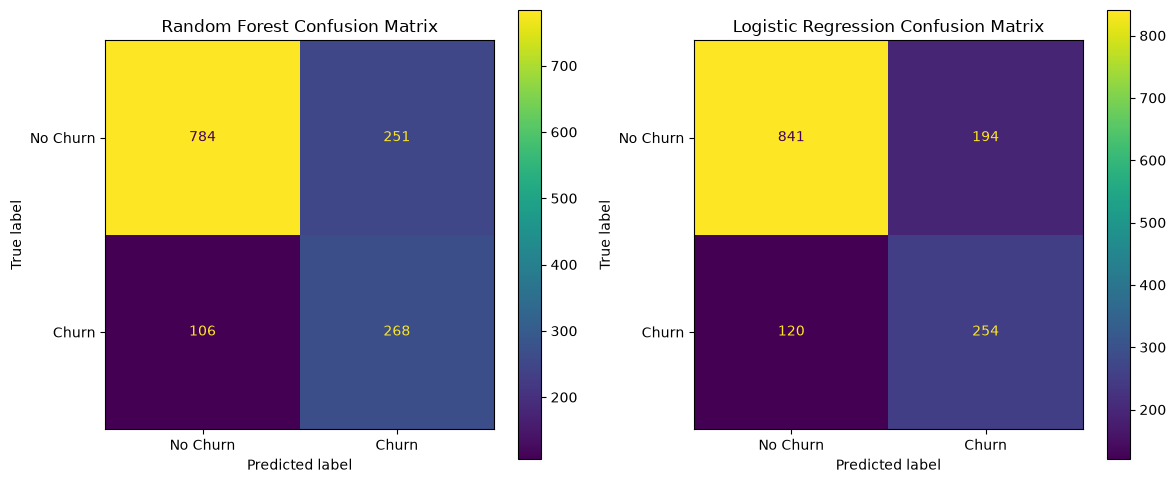

In [54]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
lr_threshold = 0.39
rf_threshold = 0.30
y_test_prob_lr = sklearn_lr.predict_proba(X_test_np)[:,1]
y_test_prob_rf = final_rf_threshold_pipeline.predict_proba(x_test)[:, 1]
y_test_pred_rf = (y_test_prob_rf >= rf_threshold).astype(int)
y_test_pred_lr = (
    y_test_prob_lr >= lr_threshold
).astype(int)
cm_lr = confusion_matrix(y_test, y_test_pred_lr)
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
print(cm_lr)
print(cm_rf)
fig,(ax1,ax2) = plt.subplots(1,2,figsize = (12,5))
disp1 = ConfusionMatrixDisplay(
    confusion_matrix = cm_rf,
    display_labels = ["No Churn","Churn"]
)
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No Churn","Churn"])
disp1.plot(ax = ax1)
ax1.set_title("Random Forest Confusion Matrix")
disp2.plot(ax = ax2)
ax2.set_title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [55]:
import numpy as np
import pandas as pd
error_df = x_test.copy()
error_df["y_true"] = y_test.values
error_df["lr_prob"] = y_test_prob_lr
error_df["lr_pred"] = y_test_pred_lr
error_df["rf_prob"] = y_test_prob_rf
error_df["rf_pred"] = y_test_pred_rf
error_df["lr_error_type"] = np.select(
    [
        (error_df["y_true"] == 1) & (error_df["lr_pred"] == 1),
        (error_df["y_true"] == 0) & (error_df["lr_pred"] == 0),
        (error_df["y_true"] == 0) & (error_df["lr_pred"] == 1),
        (error_df["y_true"] == 1) & (error_df["lr_pred"] == 0),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN",
    ],
    default="Unknown"
)

error_df["rf_error_type"] = np.select(
    [
        (error_df["y_true"] == 1) & (error_df["rf_pred"] == 1),
        (error_df["y_true"] == 0) & (error_df["rf_pred"] == 0),
        (error_df["y_true"] == 0) & (error_df["rf_pred"] == 1),
        (error_df["y_true"] == 1) & (error_df["rf_pred"] == 0),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN",
    ],
    default="Unknown"
)
print("===== Logistic Regression =====")
print(error_df["lr_error_type"].value_counts())

print("\n===== Random Forest =====")
print(error_df["rf_error_type"].value_counts())

===== Logistic Regression =====
lr_error_type
TN    841
TP    254
FP    194
FN    120
Name: count, dtype: int64

===== Random Forest =====
rf_error_type
TN    784
TP    268
FP    251
FN    106
Name: count, dtype: int64


In [56]:
lr_fn = error_df[
    (error_df["y_true"] == 1) &
    (error_df["lr_pred"] == 0)
].copy()

rf_fn = error_df[
    (error_df["y_true"] == 1) &
    (error_df["rf_pred"] == 0)
].copy()

print("Logistic Regression FN:", len(lr_fn))
print("Random Forest FN:", len(rf_fn))
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("===== Logistic Regression FN =====")
print(lr_fn[numeric_cols].describe())

print("\n===== Random Forest FN =====")
print(rf_fn[numeric_cols].describe())

Logistic Regression FN: 120
Random Forest FN: 106
===== Logistic Regression FN =====
           tenure  MonthlyCharges  TotalCharges
count  120.000000       120.00000    120.000000
mean    28.275000        63.80875   2381.062500
std     24.072706        30.73392   2475.167178
min      1.000000        18.95000     19.300000
25%      4.000000        45.95000    126.350000
50%     26.000000        59.70000   1552.775000
75%     50.500000        95.31250   4146.525000
max     72.000000       115.65000   7968.850000

===== Random Forest FN =====
           tenure  MonthlyCharges  TotalCharges
count  106.000000      106.000000    106.000000
mean    27.509434       66.232547   2285.378774
std     22.438167       30.074042   2302.621262
min      1.000000       18.950000     19.300000
25%      7.000000       48.600000    200.900000
50%     23.500000       69.175000   1633.225000
75%     46.000000       94.025000   3636.825000
max     72.000000      115.650000   7968.850000


In [57]:
categorical_cols = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]
def categorical_error_analysis(df,cols,target_name = "Error"):
    results = []
    for col in cols:
            temp = (
                df.groupby(col)["y_true"].agg(count = "count",churn_rate="mean").reset_index()#重置索引
            )
            temp["features"] = col
            results.append(temp)
    return pd.concat(results,ignore_index=True)#拼接temp小表格，不保留原来索引从新生成
lr_fn_cat = categorical_error_analysis(
    lr_fn,
    categorical_cols
)
rf_fn_cat = categorical_error_analysis(
    rf_fn,
    categorical_cols
)
print("===== Logistic Regression FN 类别特征 =====")
print(lr_fn_cat)
print("\n===== Random Forest FN 类别特征 =====")
print(rf_fn_cat)
for col in categorical_cols:
    print(f"\n===== {col} =====")

    print("Logistic FN:")
    print(lr_fn[col].value_counts(normalize=True))

    print("Random Forest FN:")
    print(rf_fn[col].value_counts(normalize=True))#统计比例

===== Logistic Regression FN 类别特征 =====
    gender  count  churn_rate          features Partner Dependents  \
0   Female     64         1.0            gender     NaN        NaN   
1     Male     56         1.0            gender     NaN        NaN   
2      NaN     63         1.0           Partner      No        NaN   
3      NaN     57         1.0           Partner     Yes        NaN   
4      NaN     79         1.0        Dependents     NaN         No   
5      NaN     41         1.0        Dependents     NaN        Yes   
6      NaN      8         1.0      PhoneService     NaN        NaN   
7      NaN    112         1.0      PhoneService     NaN        NaN   
8      NaN     69         1.0     MultipleLines     NaN        NaN   
9      NaN      8         1.0     MultipleLines     NaN        NaN   
10     NaN     43         1.0     MultipleLines     NaN        NaN   
11     NaN     51         1.0   InternetService     NaN        NaN   
12     NaN     44         1.0   InternetService   

In [58]:
lr_fp = error_df[
    (error_df["y_true"] == 0) &
    (error_df["lr_pred"] == 1)
].copy()

rf_fp = error_df[
    (error_df["y_true"] == 0) &
    (error_df["rf_pred"] == 1)
].copy()

print("Logistic Regression FP:", len(lr_fp))
print("Random Forest FP:", len(rf_fp))

print("===== Logistic Regression FP =====")
print(lr_fp[numeric_cols].describe())
print("\n===== Random Forest FP =====")
print(rf_fp[numeric_cols].describe())

for col in categorical_cols:
    print(f"\n===== {col} =====")

    print("Logistic FP:")
    print(lr_fp[col].value_counts(normalize=True))

    print("Random Forest FP:")
    print(rf_fp[col].value_counts(normalize=True))

Logistic Regression FP: 194
Random Forest FP: 251
===== Logistic Regression FP =====
           tenure  MonthlyCharges  TotalCharges
count  194.000000      194.000000    194.000000
mean    17.046392       78.790464   1503.465722
std     14.934500       19.381669   1514.097668
min      1.000000       24.200000     24.200000
25%      5.000000       69.975000    344.425000
50%     12.500000       81.175000    959.075000
75%     24.000000       91.400000   2139.187500
max     63.000000      111.500000   6479.400000

===== Random Forest FP =====
           tenure  MonthlyCharges  TotalCharges
count  251.000000       251.00000    251.000000
mean    21.832669        74.74004   1871.286454
std     19.979286        25.00699   1966.153306
min      1.000000        18.85000     18.850000
25%      5.000000        55.30000    305.325000
50%     17.000000        79.30000   1156.550000
75%     34.000000        94.70000   2760.050000
max     71.000000       114.10000   7616.000000

===== gender =====
L

In [59]:
lr_fn_mask = (
    (error_df["y_true"] == 1) &
    (error_df["lr_pred"] == 0)
)

rf_fn_mask = (
    (error_df["y_true"] == 1) &
    (error_df["rf_pred"] == 0)
)
print("LR FN:", lr_fn_mask.sum())
print("RF FN:", rf_fn_mask.sum())

print("两者共同 FN:",
      (lr_fn_mask & rf_fn_mask).sum())

print("LR 独有 FN:",
      (lr_fn_mask & ~rf_fn_mask).sum())

print("RF 独有 FN:",
      (~lr_fn_mask & rf_fn_mask).sum())

LR FN: 120
RF FN: 106
两者共同 FN: 84
LR 独有 FN: 36
RF 独有 FN: 22


In [60]:
lr_fp_mask = (
    (error_df["y_true"] == 0) &
    (error_df["lr_pred"] == 1)
)

rf_fp_mask = (
    (error_df["y_true"] == 0) &
    (error_df["rf_pred"] == 1)
)

print("LR FP:", lr_fp_mask.sum())
print("RF FP:", rf_fp_mask.sum())

print("两者共同 FP:",
      (lr_fp_mask & rf_fp_mask).sum())

print("LR 独有 FP:",
      (lr_fp_mask & ~rf_fp_mask).sum())

print("RF 独有 FP:",
      (~lr_fp_mask & rf_fp_mask).sum())

LR FP: 194
RF FP: 251
两者共同 FP: 159
LR 独有 FP: 35
RF 独有 FP: 92


In [61]:
disagree_df = error_df[
    error_df["lr_pred"] != error_df["rf_pred"]
].copy()

print("模型预测不一致的样本数：", len(disagree_df))
print(
    disagree_df[
        [
            "y_true",
            "lr_prob",
            "lr_pred",
            "rf_prob",
            "rf_pred"
        ]
    ].sort_values(
        by="y_true"
    )
)

模型预测不一致的样本数： 185
      y_true   lr_prob  lr_pred   rf_prob  rf_pred
2079       0  0.269174        0  0.360000        1
6181       0  0.276248        0  0.410000        1
3658       0  0.258995        0  0.335000        1
1517       0  0.258477        0  0.385000        1
128        0  0.194479        0  0.571095        1
...      ...       ...      ...       ...      ...
6137       1  0.159629        0  0.370000        1
3044       1  0.434837        1  0.215000        0
180        1  0.421852        1  0.210000        0
3031       1  0.328134        0  0.465000        1
3831       1  0.426215        1  0.140000        0

[185 rows x 5 columns]


In [62]:
hard_lr = error_df.copy()

hard_lr["distance_to_threshold"] = (
    hard_lr["lr_prob"] - 0.39
).abs()

print(
    hard_lr.sort_values(
        "distance_to_threshold"
    )[
        [
            "y_true",
            "lr_prob",
            "lr_pred",
            "rf_prob",
            "rf_pred",
            "distance_to_threshold"
        ]
    ].head(20)
)
hard_rf = error_df.copy()

hard_rf["distance_to_threshold"] = (
    hard_rf["rf_prob"] - 0.30
).abs()#仅保留数字没有符号

print(
    hard_rf.sort_values(
        "distance_to_threshold"
    )[
        [
            "y_true",
            "lr_prob",
            "lr_pred",
            "rf_prob",
            "rf_pred",
            "distance_to_threshold"
        ]
    ].head(20)
)

      y_true   lr_prob  lr_pred  rf_prob  rf_pred  distance_to_threshold
1583       0  0.388293        0    0.420        1               0.001707
2978       0  0.392526        1    0.345        1               0.002526
1260       0  0.387443        0    0.525        1               0.002557
2590       0  0.392888        1    0.310        1               0.002888
195        0  0.387005        0    0.525        1               0.002995
2877       1  0.386842        0    0.390        1               0.003158
1987       1  0.394059        1    0.440        1               0.004059
3856       0  0.385776        0    0.420        1               0.004224
5183       1  0.385531        0    0.345        1               0.004469
1639       1  0.394739        1    0.460        1               0.004739
2278       0  0.394754        1    0.455        1               0.004754
5207       1  0.395241        1    0.420        1               0.005241
3162       0  0.383248        0    0.145        0  

In [63]:
# ==========================================
# 误差样本画像
# ==========================================

error_groups = {
    "LR_FN": lr_fn,
    "LR_FP": lr_fp,
    "RF_FN": rf_fn,
    "RF_FP": rf_fp
}

# 数值特征
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for name, group in error_groups.items():

    print("\n" + "=" * 60)
    print(name)
    print("样本数:", len(group))

    print("\n数值特征:")
    print(
        group[numeric_cols]
        .describe()
        .loc[["mean", "50%", "std", "min", "max"]]
    )

    print("\nContract:")
    print(
        group["Contract"]
        .value_counts(normalize=True)
        .round(3)
    )

    print("\nInternetService:")
    print(
        group["InternetService"]
        .value_counts(normalize=True)
        .round(3)
    )

    print("\nPaymentMethod:")
    print(
        group["PaymentMethod"]
        .value_counts(normalize=True)
        .round(3)
    )


LR_FN
样本数: 120

数值特征:
         tenure  MonthlyCharges  TotalCharges
mean  28.275000        63.80875   2381.062500
50%   26.000000        59.70000   1552.775000
std   24.072706        30.73392   2475.167178
min    1.000000        18.95000     19.300000
max   72.000000       115.65000   7968.850000

Contract:
Contract
Month-to-month    0.658
One year          0.267
Two year          0.075
Name: proportion, dtype: float64

InternetService:
InternetService
DSL            0.425
Fiber optic    0.367
No             0.208
Name: proportion, dtype: float64

PaymentMethod:
PaymentMethod
Mailed check                 0.292
Electronic check             0.283
Bank transfer (automatic)    0.225
Credit card (automatic)      0.200
Name: proportion, dtype: float64

LR_FP
样本数: 194

数值特征:
         tenure  MonthlyCharges  TotalCharges
mean  17.046392       78.790464   1503.465722
50%   12.500000       81.175000    959.075000
std   14.934500       19.381669   1514.097668
min    1.000000       24.200000     

In [64]:
X_fe = x.copy()
X_fe["tenure_squared"] = X_fe["tenure"]**2
X_fe.head()
X_fe[["tenure", "tenure_squared"]].head()

,tenure,tenure_squared
0,1,1
1,34,1156
2,2,4
3,45,2025
4,2,4


In [65]:
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_train_sub_fe, X_val_fe, y_train_sub_fe, y_val_fe = train_test_split(
    X_train_fe,
    y_train_fe,
    test_size=0.2,
    random_state=42,
    stratify=y_train_fe
)
numeric_features_fe = [
    "SeniorCitizen",
    "tenure",
    "tenure_squared",
    "MonthlyCharges",
    "TotalCharges"
]
categorical_features_fe = categorical_features.copy()

In [66]:
preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_fe),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_fe)
    ]
)
lr_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("classifier", LogisticRegression(
            C=100,
            max_iter=3000,
            solver="lbfgs"
        ))
    ]
)

In [67]:
lr_fe.fit(X_train_sub_fe, y_train_sub_fe)
y_val_prob_fe = lr_fe.predict_proba(X_val_fe)[:,1]
thresholds = np.arange(0.05, 0.96, 0.01)

best_threshold_fe = None
best_f1_fe = -1

for threshold in thresholds:
    y_val_pred_fe = (y_val_prob_fe >= threshold).astype(int)

    f1 = f1_score(y_val_fe, y_val_pred_fe)

    if f1 > best_f1_fe:
        best_f1_fe = f1
        best_threshold_fe = threshold

print("best threshold:", best_threshold_fe)
print("best validation F1:", best_f1_fe)

best threshold: 0.36000000000000004
best validation F1: 0.6583850931677019


In [68]:
y_test_prob_fe = lr_fe.predict_proba(X_test_fe)[:, 1]

y_test_pred_fe = (
    y_test_prob_fe >= best_threshold_fe
).astype(int)
print("Accuracy:",
      accuracy_score(y_test_fe, y_test_pred_fe))

print("Precision:",
      precision_score(y_test_fe, y_test_pred_fe))

print("Recall:",
      recall_score(y_test_fe, y_test_pred_fe))

print("F1:",
      f1_score(y_test_fe, y_test_pred_fe))

print("ROC-AUC:",
      roc_auc_score(y_test_fe, y_test_prob_fe))

Accuracy: 0.7714691270404542
Precision: 0.5565217391304348
Recall: 0.6844919786096256
F1: 0.6139088729016786
ROC-AUC: 0.8419411506368029


In [69]:
from sklearn.model_selection import learning_curve#观测训练样本变化对指标影响

train_sizes, train_scores, val_scores, fit_times, score_times = learning_curve(
    lr_pipeline,
    x_train,
    y_train,
    cv=5,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1,
    return_times=True
)
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

for size, tr, va in zip(train_sizes, train_mean, val_mean):
    print(
        f"train_size={size:4d}, "
        f"train_auc={tr:.4f}, "
        f"val_auc={va:.4f}"
    )

train_size= 450, train_auc=0.8889, val_auc=0.8293
train_size=1030, train_auc=0.8681, val_auc=0.8408
train_size=1609, train_auc=0.8637, val_auc=0.8429
train_size=2189, train_auc=0.8616, val_auc=0.8443
train_size=2768, train_auc=0.8612, val_auc=0.8447
train_size=3348, train_auc=0.8567, val_auc=0.8449
train_size=3927, train_auc=0.8541, val_auc=0.8454
train_size=4507, train_auc=0.8496, val_auc=0.8457


In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# =========================
# 1. 特征定义
# =========================

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]


# =========================
# 2. 预处理
# =========================

final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)


# =========================
# 3. 最终 Logistic Regression
# =========================

final_lr = LogisticRegression(
    C=100,
    penalty="l2",
    max_iter=3000,
    solver="lbfgs"
)


# =========================
# 4. 构建完整 Pipeline
# =========================

final_lr_pipeline = Pipeline([
    ("preprocessor", final_preprocessor),
    ("classifier", final_lr)
])


# =========================
# 5. 在完整训练集上训练
# =========================

final_lr_pipeline.fit(x_train, y_train)


# =========================
# 6. 获取测试集概率
# =========================

y_test_prob_final = final_lr_pipeline.predict_proba(x_test)[:, 1]


# =========================
# 7. 使用事先确定的 threshold
# =========================

final_threshold = 0.39

y_test_pred_final = (
    y_test_prob_final >= final_threshold
).astype(int)


# =========================
# 8. 最终评价
# =========================

final_accuracy = accuracy_score(
    y_test,
    y_test_pred_final
)

final_precision = precision_score(
    y_test,
    y_test_pred_final
)

final_recall = recall_score(
    y_test,
    y_test_pred_final
)

final_f1 = f1_score(
    y_test,
    y_test_pred_final
)

final_auc = roc_auc_score(
    y_test,
    y_test_prob_final
)


print("===== Final Model =====")
print(f"Threshold : {final_threshold}")
print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1        : {final_f1:.4f}")
print(f"ROC-AUC   : {final_auc:.4f}")

print("\n===== Confusion Matrix =====")
print(confusion_matrix(
    y_test,
    y_test_pred_final
))

print("\n===== Classification Report =====")
print(classification_report(
    y_test,
    y_test_pred_final,
    digits=4
))

# 1. 获取预处理后的特征名称
feature_names = final_lr_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# 2. 获取 Logistic Regression 系数
coefficients = final_lr_pipeline.named_steps[
    "classifier"
].coef_[0]

# 3. 构造 DataFrame
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# 4. 按系数从小到大排序
coef_df_sorted = coef_df.sort_values(
    "coefficient",
    ascending=True
)

print("===== 最容易降低流失概率的特征 =====")
print(
    coef_df_sorted.head(15).to_string(index=False)
)

print("\n===== 最容易提高流失概率的特征 =====")
print(
    coef_df_sorted.tail(15)
    .sort_values("coefficient", ascending=False)
    .to_string(index=False)
)


===== Final Model =====
Threshold : 0.39
Accuracy  : 0.7743
Precision : 0.5622
Recall    : 0.6765
F1        : 0.6141
ROC-AUC   : 0.8409

===== Confusion Matrix =====
[[838 197]
 [121 253]]

===== Classification Report =====
              precision    recall  f1-score   support

           0     0.8738    0.8097    0.8405      1035
           1     0.5622    0.6765    0.6141       374

    accuracy                         0.7743      1409
   macro avg     0.7180    0.7431    0.7273      1409
weighted avg     0.7911    0.7743    0.7804      1409

===== 最容易降低流失概率的特征 =====
                                  feature  coefficient
                      num__MonthlyCharges    -2.521575
                 cat__InternetService_DSL    -1.328706
                              num__tenure    -1.318716
                   cat__Contract_Two year    -0.843204
    cat__OnlineBackup_No internet service    -0.705363
     cat__StreamingTV_No internet service    -0.705363
  cat__OnlineSecurity_No internet servi

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [73]:
# ==============================
# Final Model Comparison
# ==============================

import pandas as pd

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.7743,
        0.7509,
        0.7466
    ],
    "Precision": [
        0.5622,
        0.5273,
        0.5164
    ],
    "Recall": [
        0.6765,
        0.5936,
        0.7166
    ],
    "F1": [
        0.6141,
        0.5585,
        0.6002
    ],
    "ROC-AUC": [
        0.8409,
        np.nan,
        0.8190
    ]
})

print(final_results.to_string(index=False))

              Model  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression    0.7743     0.5622  0.6765 0.6141   0.8409
      Decision Tree    0.7509     0.5273  0.5936 0.5585      NaN
      Random Forest    0.7466     0.5164  0.7166 0.6002   0.8190
